# 03 - Modelo de Machine Learning
## Predicción de la duración de las rutas de recolección de residuos de Yarinacocha

Este notebook compara:

- Random Forest
- XGBoost
- LightGBM

**Variable objetivo:** `duracion_min`

**División:** 70 % entrenamiento, 15 % validación y 15 % prueba.

Se recomienda subir el archivo:

`residuos_yarinacocha_feature_engineering.csv`

El notebook realiza internamente la codificación de las variables categóricas para evitar problemas con el archivo de 309 columnas.

In [1]:
# 1. Instalar librerías
!pip -q install xgboost lightgbm joblib

In [2]:
# 2. Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings("ignore")

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:
# 3. Subir dataset procesado por Feature Engineering
print("Sube preferentemente: residuos_yarinacocha_feature_engineering.csv")
uploaded = files.upload()

nombre_archivo = next(iter(uploaded))
df = pd.read_csv(nombre_archivo)

print("\nArchivo cargado:", nombre_archivo)
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
display(df.head())

Sube preferentemente: residuos_yarinacocha_feature_engineering.csv


Saving residuos_yarinacocha_2026.csv to residuos_yarinacocha_2026.csv

Archivo cargado: residuos_yarinacocha_2026.csv
Filas: 733
Columnas: 18


,fecha,codigo_ruta,vehiculo,sector,hora_salida,hora_llegada,duracion_min,distancia_km,combustible_l,costo_operativo_soles,capacidad_vehicular_kg,residuos_recolectados_kg,puntos_programados,puntos_atendidos,cumplimiento_pct,latitud,longitud,incidencia
0,2026-01-01,R003,VH04,San José,06:20,09:46,206,41.95,13.57,348.39,6000,3503.32,40,40,100.0,-8.382415,-74.602529,Demora operativa
1,2026-01-01,R004,VH02,La Restinga,07:27,09:57,150,30.83,8.37,228.71,5000,3861.81,45,45,100.0,-8.314313,-74.544781,Ninguna
2,2026-01-02,R004,VH01,La Restinga,06:26,08:56,150,38.47,11.82,302.69,4500,3398.72,39,39,100.0,-8.363072,-74.596332,Ninguna
3,2026-01-02,R005,VH03,Las Palmeras,07:17,10:11,174,41.37,13.01,327.39,5500,4348.02,42,42,100.0,-8.351885,-74.573015,Ninguna
4,2026-01-03,R005,VH02,Las Palmeras,06:27,09:34,187,48.09,13.47,336.99,5000,4619.23,33,33,100.0,-8.369644,-74.602894,Ninguna


In [4]:
# 4. Comprobar variable objetivo
TARGET = "duracion_min"

if TARGET not in df.columns:
    raise ValueError(
        f"No se encontró '{TARGET}'. "
        "Sube el archivo residuos_yarinacocha_feature_engineering.csv "
        "o un archivo que conserve la columna duracion_min."
    )

print("Variable objetivo encontrada:", TARGET)
print("\nEstadísticas de duración:")
display(df[TARGET].describe())

Variable objetivo encontrada: duracion_min

Estadísticas de duración:


,duracion_min
count,733.000000
mean,199.698499
std,44.273065
min,150.000000
25%,160.000000
50%,191.000000
75%,225.000000
max,431.000000


## Evitar fuga de información

Como queremos predecir `duracion_min`, no podemos utilizar variables que ya contienen directa o indirectamente la duración real.

Por ello se eliminan:

- `duracion_min` de X porque es la variable objetivo.
- `tiempo_por_punto`, porque se calcula usando la duración.
- `hora_llegada`, porque junto con la hora de salida permite conocer la duración real.
- la fecha original en texto si ya existen variables de año, mes y día.

In [5]:
# 5. Preparar X e y evitando fuga de información

y = pd.to_numeric(df[TARGET], errors="coerce")

columnas_excluir = [TARGET]

# Variable creada directamente a partir de la duración
columnas_excluir += [
    c for c in df.columns
    if c == "tiempo_por_punto" or c.startswith("tiempo_por_punto_")
]

# Hora de llegada: contiene información posterior al recorrido
columnas_excluir += [
    c for c in df.columns
    if c == "hora_llegada" or c.startswith("hora_llegada_")
]

# Si la fecha ya fue descompuesta, quitamos el texto original
if "fecha" in df.columns and any(c.startswith("fecha_") for c in df.columns):
    columnas_excluir.append("fecha")

X = df.drop(columns=list(set(columnas_excluir)), errors="ignore").copy()

# Eliminar filas cuya variable objetivo sea inválida
mask = y.notna()
X = X.loc[mask].reset_index(drop=True)
y = y.loc[mask].reset_index(drop=True)

print("Registros utilizados:", len(X))
print("Variables predictoras iniciales:", X.shape[1])
print("Columnas excluidas:", sorted(set(columnas_excluir)))

Registros utilizados: 733
Variables predictoras iniciales: 16
Columnas excluidas: ['duracion_min', 'hora_llegada']


In [6]:
# 6. División 70 % / 15 % / 15 %

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Entrenamiento:", len(X_train), f"({len(X_train)/len(X)*100:.1f} %)")
print("Validación:", len(X_val), f"({len(X_val)/len(X)*100:.1f} %)")
print("Prueba:", len(X_test), f"({len(X_test)/len(X)*100:.1f} %)")

Entrenamiento: 513 (70.0 %)
Validación: 110 (15.0 %)
Prueba: 110 (15.0 %)


In [7]:
# 7. Identificar columnas numéricas y categóricas

columnas_numericas = X_train.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Variables numéricas:", len(columnas_numericas))
print("Variables categóricas:", len(columnas_categoricas))

print("\nCategóricas:")
print(columnas_categoricas)

Variables numéricas: 10
Variables categóricas: 6

Categóricas:
['fecha', 'codigo_ruta', 'vehiculo', 'sector', 'hora_salida', 'incidencia']


In [8]:
# 8. Preprocesamiento

# Compatibilidad con distintas versiones de scikit-learn
try:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocesador = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            columnas_numericas
        ),
        (
            "cat",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", codificador)
            ]),
            columnas_categoricas
        )
    ],
    remainder="drop"
)

print("Preprocesador configurado correctamente.")

Preprocesador configurado correctamente.


In [9]:
# 9. Función de evaluación

def evaluar(nombre, modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)
    mae = mean_absolute_error(y_eval, pred)
    rmse = np.sqrt(mean_squared_error(y_eval, pred))
    r2 = r2_score(y_eval, pred)

    return {
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }, pred

In [10]:
# 10. Random Forest

modelo_rf = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf.fit(X_train, y_train)

res_rf, pred_rf = evaluar(
    "Random Forest",
    modelo_rf,
    X_val,
    y_val
)

print(res_rf)

{'Modelo': 'Random Forest', 'MAE': 18.41212121212121, 'RMSE': np.float64(24.280355874948402), 'R2': 0.6795975827548413}


In [11]:
# 11. XGBoost

modelo_xgb = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", XGBRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_xgb.fit(X_train, y_train)

res_xgb, pred_xgb = evaluar(
    "XGBoost",
    modelo_xgb,
    X_val,
    y_val
)

print(res_xgb)

{'Modelo': 'XGBoost', 'MAE': 19.10243034362793, 'RMSE': np.float64(24.756795547510787), 'R2': 0.6669000387191772}


In [12]:
# 12. LightGBM

modelo_lgbm = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", LGBMRegressor(
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ))
])

modelo_lgbm.fit(X_train, y_train)

res_lgbm, pred_lgbm = evaluar(
    "LightGBM",
    modelo_lgbm,
    X_val,
    y_val
)

print(res_lgbm)

{'Modelo': 'LightGBM', 'MAE': 18.7536425512851, 'RMSE': np.float64(24.64914157971479), 'R2': 0.6697907104232976}


In [13]:
# 13. Comparar modelos en VALIDACIÓN

resultados = pd.DataFrame([
    res_rf,
    res_xgb,
    res_lgbm
])

resultados = resultados.sort_values(
    by=["RMSE", "MAE"],
    ascending=[True, True]
).reset_index(drop=True)

print("=== RESULTADOS DE VALIDACIÓN ===")
display(resultados)

mejor_nombre = resultados.loc[0, "Modelo"]
print("\nMejor modelo según RMSE:", mejor_nombre)

=== RESULTADOS DE VALIDACIÓN ===


,Modelo,MAE,RMSE,R2
0,Random Forest,18.412121,24.280356,0.679598
1,LightGBM,18.753643,24.649142,0.669791
2,XGBoost,19.102430,24.756796,0.666900



Mejor modelo según RMSE: Random Forest


In [14]:
# 14. Seleccionar el mejor pipeline

modelos = {
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb,
    "LightGBM": modelo_lgbm
}

mejor_pipeline = modelos[mejor_nombre]

# Reentrenar con entrenamiento + validación
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

mejor_pipeline.fit(X_train_final, y_train_final)

resultado_test, pred_test = evaluar(
    mejor_nombre,
    mejor_pipeline,
    X_test,
    y_test
)

print("=== RESULTADO FINAL EN PRUEBA ===")
print("Modelo:", mejor_nombre)
print(f"MAE:  {resultado_test['MAE']:.4f} minutos")
print(f"RMSE: {resultado_test['RMSE']:.4f} minutos")
print(f"R²:   {resultado_test['R2']:.4f}")

=== RESULTADO FINAL EN PRUEBA ===
Modelo: Random Forest
MAE:  16.5222 minutos
RMSE: 22.6479 minutos
R²:   0.7306


In [15]:
# 15. Valores reales vs predichos

comparacion = pd.DataFrame({
    "Duracion_real_min": y_test.to_numpy(),
    "Duracion_predicha_min": pred_test,
    "Error_absoluto_min": np.abs(y_test.to_numpy() - pred_test)
})

display(comparacion.head(15))

,Duracion_real_min,Duracion_predicha_min,Error_absoluto_min
0,252,237.376667,14.623333
1,156,159.503333,3.503333
2,194,179.516667,14.483333
3,188,224.850000,36.850000
4,278,287.150000,9.150000
5,212,168.803333,43.196667
6,266,216.540000,49.460000
7,150,161.136667,11.136667
8,209,247.206667,38.206667
9,150,155.553333,5.553333


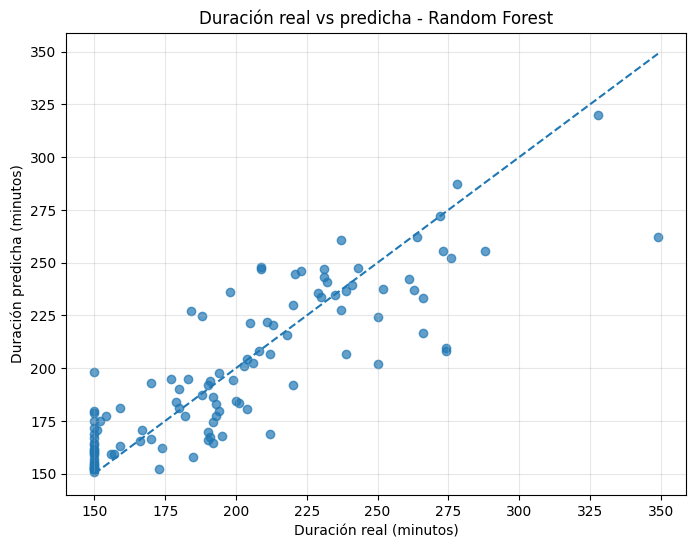

In [16]:
# 16. Gráfico valores reales vs predichos

plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_test, alpha=0.7)

lim_inf = min(y_test.min(), pred_test.min())
lim_sup = max(y_test.max(), pred_test.max())

plt.plot(
    [lim_inf, lim_sup],
    [lim_inf, lim_sup],
    linestyle="--"
)

plt.xlabel("Duración real (minutos)")
plt.ylabel("Duración predicha (minutos)")
plt.title(f"Duración real vs predicha - {mejor_nombre}")
plt.grid(alpha=0.3)
plt.show()

=== 20 VARIABLES MÁS IMPORTANTES ===


,Variable,Importancia
2,num__costo_operativo_soles,0.604881
1,num__combustible_l,0.136344
0,num__distancia_km,0.042957
9,num__longitud,0.027097
4,num__residuos_recolectados_kg,0.023258
8,num__latitud,0.020724
6,num__puntos_atendidos,0.011319
7,num__cumplimiento_pct,0.010234
5,num__puntos_programados,0.009827
3,num__capacidad_vehicular_kg,0.005266


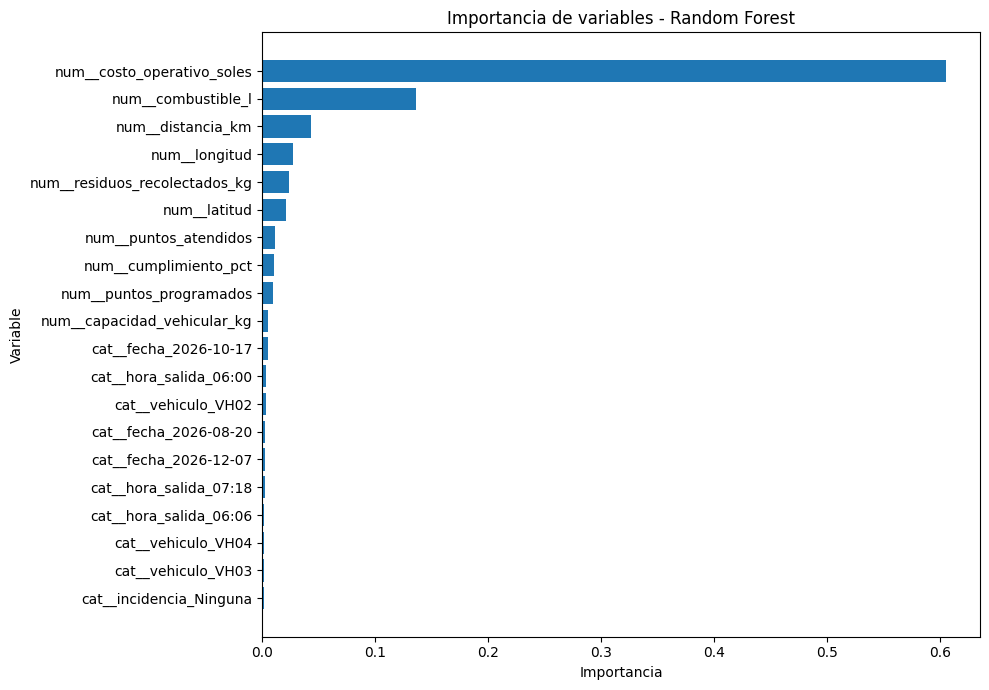

In [17]:
# 17. Importancia de variables

prep = mejor_pipeline.named_steps["preprocesamiento"]
modelo_final = mejor_pipeline.named_steps["modelo"]

try:
    nombres_variables = prep.get_feature_names_out()
except Exception:
    nombres_variables = [f"Variable_{i}" for i in range(len(modelo_final.feature_importances_))]

if hasattr(modelo_final, "feature_importances_"):
    importancia = pd.DataFrame({
        "Variable": nombres_variables,
        "Importancia": modelo_final.feature_importances_
    }).sort_values("Importancia", ascending=False).head(20)

    print("=== 20 VARIABLES MÁS IMPORTANTES ===")
    display(importancia)

    orden = importancia.sort_values("Importancia")
    plt.figure(figsize=(10, 7))
    plt.barh(orden["Variable"], orden["Importancia"])
    plt.xlabel("Importancia")
    plt.ylabel("Variable")
    plt.title(f"Importancia de variables - {mejor_nombre}")
    plt.tight_layout()
    plt.show()

In [18]:
# 18. Guardar archivos

resultados.to_csv(
    "comparacion_modelos_validacion.csv",
    index=False
)

comparacion.to_csv(
    "predicciones_modelo_final.csv",
    index=False
)

joblib.dump(
    mejor_pipeline,
    "mejor_modelo_duracion_rutas.pkl"
)

print("Archivos creados correctamente:")
print("- comparacion_modelos_validacion.csv")
print("- predicciones_modelo_final.csv")
print("- mejor_modelo_duracion_rutas.pkl")

Archivos creados correctamente:
- comparacion_modelos_validacion.csv
- predicciones_modelo_final.csv
- mejor_modelo_duracion_rutas.pkl


In [19]:
# 19. Descargar resultados

files.download("comparacion_modelos_validacion.csv")
files.download("predicciones_modelo_final.csv")
files.download("mejor_modelo_duracion_rutas.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cómo interpretar los resultados

Para seleccionar el mejor modelo:

- **MAE:** cuanto menor, mejor.
- **RMSE:** cuanto menor, mejor.
- **R²:** cuanto más próximo a 1, mejor.

El conjunto de validación se utiliza para comparar Random Forest, XGBoost y LightGBM.

Después de seleccionar el mejor algoritmo, se vuelve a entrenar con los datos de entrenamiento y validación juntos y se evalúa finalmente con el conjunto de prueba.